# Report Figures and Extra Metrics

This notebook recomputes every number and figure in the final report that is **not** printed directly by the modeling notebooks.
It does **not** train any models. It only reads files that already exist:

| File | Made by |
|---|---|
| `processed/final_modeling_dataset.csv` | `build_modeling_dataset.ipynb` |
| `models/locked_test/q1_results.csv`, `q2_results.csv` | `shoreline_model_comparison_holdout_simplified.ipynb` |
| `models/locked_test/*/test_predictions.csv` | same |
| `models/locked_test/*/gbt_*.pkl`, `linear_*.pkl` | same |

**Run time:** under a minute.

**What it produces (and where each result appears in the report):**

1. Dataset summary numbers (Section 4: Data)
2. Figure: distribution of winter shoreline change (Section 4.6)
3. Figure: average change per winter vs. RONI (Section 4.6)
4. All six evaluation metrics on the locked test sets (Section 6, Tables for Question 1 and Question 2)
5. Change in R² from adding RONI (Section 6.2)
6. Linear regression coefficients (Section 6.3)
7. Figure: training vs. cross-validation vs. test R², the over/underfitting check (Section 6.4)
8. GBT settings chosen by the grid search (Section 6.5)
9. Test error in each locked winter (Section 6.6)

## 1. Setup

In [1]:
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import (r2_score, mean_absolute_error, root_mean_squared_error,
                             median_absolute_error, explained_variance_score, max_error)

warnings.filterwarnings("ignore")   # hide scikit-learn version warnings when loading models

ROOT_DIR   = Path.cwd().parent                      # this notebook lives in scripts/
DATA_PATH  = ROOT_DIR / "processed" / "final_modeling_dataset.csv"
LOCKED_DIR = ROOT_DIR / "models" / "locked_test"
Q1_FOLDER  = LOCKED_DIR / "q1_last_4_winters"
Q2_FOLDER  = LOCKED_DIR / "q2_22_random_sections"
FIG_DIR    = ROOT_DIR / "Claude outputs" / "figures"  # the report's figures folder
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "shoreline_change_m"
Q1_TEST_WINTERS = ["2017-2018", "2018-2019", "2019-2020", "2020-2021"]

Figure style used for every report figure: serif font to match the IEEE template, and three colors that are easy to tell apart, including for colorblind readers.

In [2]:
plt.rcParams.update({
    "font.family": "serif", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
BLUE, ORANGE, GREEN, GRAY = "#2a78d6", "#e0742b", "#1a9e77", "#52514e"

## 2. Dataset summary numbers (Section 4)

We load the modeling dataset **before** removing outliers, because Section 4 describes the full dataset.

In [3]:
full = pd.read_csv(DATA_PATH)
y_full = full[TARGET]

print("Rows:", len(full))
print("Transects:", full["transect_id"].nunique())
print("Winters:", full["winter"].nunique(), f"({full['winter'].min()} to {full['winter'].max()})")
print("Missing beach slope:", full["beach_slope"].isna().sum(),
      "rows from", full.loc[full["beach_slope"].isna(), "transect_id"].nunique(), "transects")
print()
print(f"Mean change:   {y_full.mean():.2f} m")
print(f"Median change: {y_full.median():.2f} m")
print(f"Middle half:   {y_full.quantile(0.25):.1f} m to {y_full.quantile(0.75):.1f} m")
print(f"Share of transect-winters that eroded (change < 0): {(y_full < 0).mean():.0%}")
print(f"Share within ±10 m (about the satellite error):     {(y_full.abs() <= 10).mean():.0%}")

Rows: 60864
Transects: 3220
Winters: 21 (2000-2001 to 2020-2021)
Missing beach slope: 740 rows from 38 transects

Mean change:   -7.17 m
Median change: -6.35 m
Middle half:   -12.9 m to -0.8 m
Share of transect-winters that eroded (change < 0): 78%
Share within ±10 m (about the satellite error):     61%


**Outliers:** rows with more than 50 m of change in one winter (Section 4.5).

In [4]:
is_outlier = y_full.abs() > 50
print("Outlier rows:", is_outlier.sum(), f"({is_outlier.mean():.2%})")
print("Rows left:", (~is_outlier).sum())
print("\nSections with the most outliers:")
print(full.loc[is_outlier, "transect_id"].str[:11].value_counts().head(3))

Outlier rows: 280 (0.46%)
Rows left: 60584

Sections with the most outliers:
transect_id
usa_CA_0026    45
usa_CA_0088    40
usa_CA_0084    31
Name: count, dtype: int64


## 3. Figure: distribution of winter shoreline change

Saved as `target_hist.pdf` (Fig. 1 in the report).

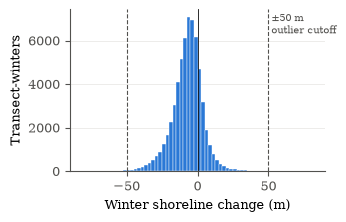

In [5]:
fig, ax = plt.subplots(figsize=(3.5, 2.3))
ax.hist(y_full.clip(-120, 135), bins=np.arange(-120, 136, 2.5), color=BLUE, edgecolor="white", linewidth=0.3)
for x in (-50, 50):
    ax.axvline(x, color=GRAY, ls="--", lw=0.8)        # outlier cutoff
ax.axvline(0, color="#0b0b0b", lw=0.6)
ax.set_xlim(-90, 90)
ax.set_xlabel("Winter shoreline change (m)")
ax.set_ylabel("Transect-winters")
ax.text(52, ax.get_ylim()[1] * 0.85, "±50 m\noutlier cutoff", fontsize=7, color=GRAY)
ax.grid(axis="y", color="#e6e5e1", lw=0.5)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / "target_hist.pdf")
plt.show()

## 4. Figure: average change per winter vs. RONI

Each dot is one winter: the average change across all transects that winter. Saved as `roni_winter.pdf` (Fig. 2).

Correlation between RONI and average winter change: -0.10


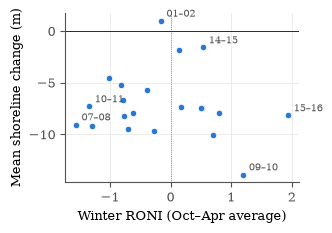

,winter,mean_change,RONI
0,2000-2001,-9.45,-0.70
1,2001-2002,1.00,-0.16
2,2002-2003,-7.94,0.80
3,2003-2004,-7.33,0.18
4,2004-2005,-7.44,0.52
5,2005-2006,-8.25,-0.76
6,2006-2007,-7.48,0.50
7,2007-2008,-9.04,-1.56
8,2008-2009,-5.24,-0.82
9,2009-2010,-13.88,1.20


In [6]:
winters = full.groupby("winter").agg(mean_change=(TARGET, "mean"), RONI=("RONI", "first")).reset_index()
print(f"Correlation between RONI and average winter change: {winters['RONI'].corr(winters['mean_change']):.2f}")

fig, ax = plt.subplots(figsize=(3.5, 2.4))
ax.scatter(winters["RONI"], winters["mean_change"], s=22, color=BLUE, edgecolor="white", linewidth=0.6, zorder=3)
labeled = ["2009-2010", "2015-2016", "2007-2008", "2001-2002", "2014-2015", "2010-2011"]
for _, row in winters[winters["winter"].isin(labeled)].iterrows():
    short = row["winter"][2:4] + "–" + row["winter"][7:9]     # "2009-2010" -> "09–10"
    ax.annotate(short, (row["RONI"], row["mean_change"]), xytext=(4, 3),
                textcoords="offset points", fontsize=7, color=GRAY)
ax.axhline(0, color="#0b0b0b", lw=0.6)
ax.axvline(0, color=GRAY, lw=0.5, ls=":")
ax.set_xlabel("Winter RONI (Oct–Apr average)")
ax.set_ylabel("Mean shoreline change (m)")
ax.grid(color="#e6e5e1", lw=0.5)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG_DIR / "roni_winter.pdf")
plt.show()

winters.round(2)

## 5. All six metrics on the locked test sets (Section 6 tables)

The modeling notebook reports R² and MAE. The assignment asks for as many metrics as possible, so here we add four more,
computed from the saved test predictions:

| Metric | What it tells you |
|---|---|
| **R²** | Share of the variation the model explains (1 = perfect, 0 = no better than the average) |
| **MAE** | Average size of an error, in meters |
| **RMSE** | Like MAE, but big misses count extra |
| **Median absolute error** | Typical error with extreme misses ignored |
| **Explained variance** | Like R², but ignores predictions that are all shifted by the same amount |
| **Max error** | The single worst prediction |

In [7]:
INFO_COLUMNS = ["transect_id", "section", "winter", "RONI", TARGET]

def six_metrics(folder):
    """Score every model's saved test predictions with all six metrics."""
    predictions = pd.read_csv(folder / "test_predictions.csv")
    actual = predictions[TARGET]
    models = [c for c in predictions.columns if c not in INFO_COLUMNS]
    table = pd.DataFrame({
        model: {
            "R²": r2_score(actual, predictions[model]),
            "MAE (m)": mean_absolute_error(actual, predictions[model]),
            "RMSE (m)": root_mean_squared_error(actual, predictions[model]),
            "Median AE (m)": median_absolute_error(actual, predictions[model]),
            "Explained variance": explained_variance_score(actual, predictions[model]),
            "Max error (m)": max_error(actual, predictions[model]),
        }
        for model in models
    }).T
    return table

q1_metrics = six_metrics(Q1_FOLDER)
q2_metrics = six_metrics(Q2_FOLDER)

**Check:** our R² and MAE should match the modeling notebook's saved results exactly. If they do, the other four metrics come from the same predictions.

In [8]:
q1_results = pd.read_csv(LOCKED_DIR / "q1_results.csv").set_index("model")
q2_results = pd.read_csv(LOCKED_DIR / "q2_results.csv").set_index("model")

for name, metrics, results in [("Question 1", q1_metrics, q1_results), ("Question 2", q2_metrics, q2_results)]:
    r2_matches  = np.allclose(metrics["R²"], results.loc[metrics.index, "Test R²"])
    mae_matches = np.allclose(metrics["MAE (m)"], results.loc[metrics.index, "Test MAE (m)"])
    print(f"{name}: R² matches = {r2_matches}, MAE matches = {mae_matches}")

Question 1: R² matches = True, MAE matches = True
Question 2: R² matches = True, MAE matches = True


### Question 1 (new winter): training, cross-validation, and all six test metrics

In [9]:
q1_table = q1_results[["Train R²", "CV R²", "CV MAE (m)"]].join(q1_metrics)
q1_table.round(3)

,Train R²,CV R²,CV MAE (m),R²,MAE (m),RMSE (m),Median AE (m),Explained variance,Max error (m)
model,,,,,,,,,
Baseline: overall average,0.000,-0.009,7.969,-0.010,8.152,10.745,6.431,0.000,57.100
Baseline: transect average,0.524,0.451,5.844,0.449,6.070,7.939,4.868,0.460,61.172
Linear: beach,0.036,0.024,7.820,0.034,7.927,10.509,6.243,0.045,58.641
Linear: beach + wave,0.062,0.049,7.746,0.054,7.872,10.398,6.279,0.066,57.255
Linear: beach + wave + RONI,0.063,0.040,7.797,0.055,7.871,10.393,6.253,0.065,57.537
GAM: beach,0.097,0.083,7.546,0.067,7.740,10.327,5.968,0.079,63.193
GAM: beach + wave,0.125,0.107,7.480,0.082,7.705,10.243,5.955,0.095,61.286
GAM: beach + wave + RONI,0.152,0.074,7.667,0.125,7.437,9.999,5.653,0.127,61.292
RF: beach,0.362,0.315,6.483,0.302,6.772,8.934,5.363,0.314,62.499


### Question 2 (new coastline)

In [10]:
q2_table = q2_results[["Train R²", "CV R²", "CV MAE (m)"]].join(q2_metrics)
q2_table.round(3)

,Train R²,CV R²,CV MAE (m),R²,MAE (m),RMSE (m),Median AE (m),Explained variance,Max error (m)
model,,,,,,,,,
Baseline: overall average,0.000,-0.013,8.073,-0.010,7.760,10.453,5.933,0.000,53.762
Linear: beach,0.034,-0.002,8.008,0.037,7.596,10.206,5.791,0.046,56.042
Linear: beach + wave,0.064,0.010,8.009,0.040,7.612,10.190,5.875,0.052,54.828
GAM: beach,0.087,0.028,7.864,0.090,7.362,9.924,5.621,0.095,56.098
GAM: beach + wave,0.128,0.033,7.907,0.004,7.661,10.379,5.853,0.022,62.343
RF: beach,0.375,-0.046,8.215,-0.013,7.773,10.470,5.914,-0.006,61.491
RF: beach + wave,0.445,-0.029,8.207,0.017,7.681,10.313,5.845,0.029,62.180
GBT: beach,0.270,-0.035,8.140,-0.002,7.733,10.411,5.901,0.003,64.349
GBT: beach + wave,0.402,-0.039,8.235,0.009,7.756,10.356,5.981,0.017,61.677


## 6. Change in R² from adding RONI (Section 6.2)

For each model type, R² **with** RONI minus R² **without** RONI. Negative means RONI made predictions worse.
We show it for both cross-validation (17 training winters) and the locked test (4 winters).

In [11]:
PAIRS = {
    "Transect average + linear": ("Baseline: transect average", "Transect average + linear RONI"),
    "Transect average + GBT":    ("Transect average + GBT beach + wave (control)", "Transect average + GBT beach + wave + RONI"),
    "Linear regression":         ("Linear: beach + wave", "Linear: beach + wave + RONI"),
    "GAM":                       ("GAM: beach + wave",    "GAM: beach + wave + RONI"),
    "Random forest":             ("RF: beach + wave",     "RF: beach + wave + RONI"),
    "GBT":                       ("GBT: beach + wave",    "GBT: beach + wave + RONI"),
}
roni_effect = pd.DataFrame({
    family: {
        "Cross-validation": q1_results.loc[with_roni, "CV R²"] - q1_results.loc[without, "CV R²"],
        "Locked test":      q1_results.loc[with_roni, "Test R²"] - q1_results.loc[without, "Test R²"],
    }
    for family, (without, with_roni) in PAIRS.items()
}).T
roni_effect.round(3)

,Cross-validation,Locked test
Transect average + linear,-0.009,0.001
Transect average + GBT,-0.077,-0.010
Linear regression,-0.009,0.001
GAM,-0.034,0.043
Random forest,-0.141,-0.087
GBT,-0.100,-0.029


## 7. Linear regression coefficients (Section 6.3)

The final linear model (trained on all 17 training winters) is one equation. The features were standardized inside the
pipeline, so each coefficient is **meters of change per one standard deviation** of that feature. Negative = more erosion.

In [12]:
linear = joblib.load(Q1_FOLDER / "linear_beach_wave_roni.pkl")
features = ["BeachWidth_m", "beach_slope", "shore_orientation_sin", "shore_orientation_cos",
            "winter_wave_power", "wave_dir_sin", "wave_dir_cos", "RONI"]
scaler, regression = linear[1], linear[-1]      # pipeline steps: imputer, scaler, linear regression

coefficients = pd.DataFrame({
    "m per standard deviation": regression.coef_,
    "m per unit of the feature": regression.coef_ / scaler.scale_,
}, index=features)
print(f"Intercept: {regression.intercept_:.2f} m")
coefficients.round(3)

Intercept: -7.32 m


,m per standard deviation,m per unit of the feature
BeachWidth_m,-0.578,-0.010
beach_slope,1.287,48.316
shore_orientation_sin,-1.171,-2.975
shore_orientation_cos,2.322,8.010
winter_wave_power,-1.134,-0.858
wave_dir_sin,-0.537,-1.953
wave_dir_cos,-3.959,-14.462
RONI,-0.341,-0.370


**The two-stage model's RONI coefficient.** That model first removes each transect's average change, then fits one RONI
coefficient to what's left. Refitting that second step here gives the same number, without needing the custom model class.

In [13]:
data = full[full[TARGET].abs() <= 50]                          # same outlier rule as the models
train = data[~data["winter"].isin(Q1_TEST_WINTERS)]            # the 17 training winters
leftover = train[TARGET] - train.groupby("transect_id")[TARGET].transform("mean")
slope, intercept = np.polyfit(train["RONI"], leftover, 1)
print(f"RONI coefficient after removing each transect's average: {slope:.2f} m per unit of RONI")

RONI coefficient after removing each transect's average: -0.39 m per unit of RONI


## 8. Figure: over/underfitting check (Section 6.4)

For each Question 1 model: R² on its own training data, in cross-validation, and on the locked test.
A long gray line means the model scored much better on data it learned from than on winters it hadn't seen (overfitting).
Saved as `overfitting.pdf` (Fig. 3).

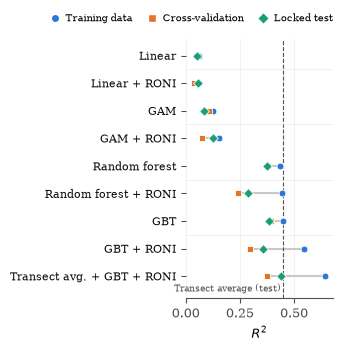

In [14]:
ROWS = [("Linear: beach + wave", "Linear"), ("Linear: beach + wave + RONI", "Linear + RONI"),
        ("GAM: beach + wave", "GAM"), ("GAM: beach + wave + RONI", "GAM + RONI"),
        ("RF: beach + wave", "Random forest"), ("RF: beach + wave + RONI", "Random forest + RONI"),
        ("GBT: beach + wave", "GBT"), ("GBT: beach + wave + RONI", "GBT + RONI"),
        ("Transect average + GBT beach + wave + RONI", "Transect avg. + GBT + RONI")]
SCORES = [("Train R²", "Training data", BLUE, "o"),
          ("CV R²", "Cross-validation", ORANGE, "s"),
          ("Test R²", "Locked test", GREEN, "D")]

fig, ax = plt.subplots(figsize=(3.5, 3.5))
n = len(ROWS)
for i, (model, label) in enumerate(ROWS):
    y = n - 1 - i
    values = [q1_results.loc[model, column] for column, _, _, _ in SCORES]
    ax.plot([min(values), max(values)], [y, y], color="#c9c8c3", lw=1.5, zorder=1)     # the gap
    for (column, _, color, marker), value in zip(SCORES, values):
        ax.scatter(value, y, color=color, marker=marker, s=24, zorder=3, edgecolor="white", linewidth=0.6)

baseline = q1_results.loc["Baseline: transect average", "Test R²"]
ax.axvline(baseline, color=GRAY, ls="--", lw=0.8)
ax.text(baseline - 0.008, -0.45, "Transect average (test)", fontsize=6.5, color=GRAY, ha="right", va="center")
ax.set_yticks(range(n))
ax.set_yticklabels([label for _, label in ROWS][::-1], color="#0b0b0b", fontsize=8)
for y in (1.5, 3.5, 5.5, 7.5):
    ax.axhline(y, color="#ecebe7", lw=0.5)
ax.spines["left"].set_visible(False)
ax.set_xlabel("$R^2$")
ax.set_xlim(0, 0.68)
ax.set_ylim(-0.8, n - 0.4)
ax.grid(axis="x", color="#ecebe7", lw=0.5)
ax.set_axisbelow(True)
handles = [Line2D([], [], ls="", marker=marker, color=color, markeredgecolor="white", markersize=6, label=label)
           for _, label, color, marker in SCORES]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, fontsize=7,
           handletextpad=0.1, columnspacing=1.0, bbox_to_anchor=(0.55, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIG_DIR / "overfitting.pdf")
plt.show()

## 9. GBT settings chosen by the grid search (Section 6.5)

Each saved GBT is the winner of the grid search run on all of its training data (step 3).
`n_iter_` is how many trees it kept. 300 means early stopping never triggered.

In [15]:
gbt_files = [(Q1_FOLDER, "Question 1", ["gbt_beach.pkl", "gbt_beach_wave.pkl", "gbt_beach_wave_roni.pkl"]),
             (Q2_FOLDER, "Question 2", ["gbt_beach.pkl", "gbt_beach_wave.pkl"])]
settings = []
for folder, question, files in gbt_files:
    for file in files:
        gbt = joblib.load(folder / file)
        settings.append({"question": question, "model": file,
                         "leaves per tree": gbt.max_leaf_nodes,
                         "min rows per leaf": gbt.min_samples_leaf,
                         "trees kept": gbt.n_iter_,
                         "learning rate": gbt.learning_rate})
pd.DataFrame(settings)

,question,model,leaves per tree,min rows per leaf,trees kept,learning rate
0,Question 1,gbt_beach.pkl,31,100,300,0.05
1,Question 1,gbt_beach_wave.pkl,31,100,300,0.05
2,Question 1,gbt_beach_wave_roni.pkl,31,100,300,0.05
3,Question 2,gbt_beach.pkl,15,500,300,0.05
4,Question 2,gbt_beach_wave.pkl,15,100,300,0.05


## 10. Test error in each locked winter (Section 6.6)

MAE in each of the 4 locked winters, with and without RONI. Does RONI help more in El Niño or La Niña winters?

In [16]:
q1_predictions = pd.read_csv(Q1_FOLDER / "test_predictions.csv")
models = ["Baseline: transect average", "Transect average + linear RONI",
          "GAM: beach + wave", "GAM: beach + wave + RONI",
          "RF: beach + wave", "RF: beach + wave + RONI",
          "GBT: beach + wave", "GBT: beach + wave + RONI"]

by_winter = {}
for winter, rows in q1_predictions.groupby("winter"):
    by_winter[winter] = {"RONI": rows["RONI"].iloc[0], "Mean actual change (m)": rows[TARGET].mean()}
    for model in models:
        by_winter[winter][model] = mean_absolute_error(rows[TARGET], rows[model])
pd.DataFrame(by_winter).round(2)

,2017-2018,2018-2019,2019-2020,2020-2021
RONI,-1.02,0.70,0.14,-1.30
Mean actual change (m),-4.48,-9.76,-1.81,-9.11
Baseline: transect average,5.88,6.32,6.92,5.17
Transect average + linear RONI,5.77,6.23,6.97,5.31
GAM: beach + wave,7.07,8.95,7.52,7.33
GAM: beach + wave + RONI,6.91,8.96,6.49,7.46
RF: beach + wave,6.11,7.12,6.78,5.73
RF: beach + wave + RONI,6.05,8.13,6.88,6.36
GBT: beach + wave,6.07,7.08,6.82,5.68
GBT: beach + wave + RONI,5.65,7.15,6.92,6.52
